# Aspect-Based Sentiment Analysis — Comparative Evaluation
This notebook demonstrates and compares three ABSA implementations built for Yelp Reviews.

Implementations:
- LexiconABSA — rule-based (spaCy + VADER)
- TransformerABSA — hybrid DeBERTa models
- LLMABSA — local LLM via Ollama

It evaluates their outputs on:
- Aspect detection quality
- Sentiment classification accuracy
- Runtime performance
- Interpretability and trade-offs


In [1]:
import json
import time
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

from src.lexicon_absa import LexiconABSA
from src.transformer_absa import TransformerABSA
from src.llm_absa import LLMABSA

C:\Users\lesle\PycharmProjects\SentimentProject\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Load Yelp Sample Dataset
df = pd.read_json("../data/yelp_sample_20k.json", lines=True)
df.head()

,text,stars
0,Fresh spring water... check!\nHugely portioned...,5
1,"I tried their decaf latte which was tasty, foa...",4
2,Amazing Bagels!! My favorite place ever! Super...,5
3,"Well, I visited UAL for the first time today b...",5
4,Eight of us came here for brunch for my birthd...,4


In [3]:
# Sample 20 reviews for evaluation (for runtime reasons)

sample_df = df.sample(20, random_state=42).reset_index(drop=True)
sample_df.head()

,text,stars
0,I used to get take-out from here once a week b...,5
1,Consistent service and quality of food. My dau...,5
2,We were visiting and came out to Play two nigh...,4
3,We got the breakfast sandwiches and potato sid...,5
4,Food court has only 2 options and 1 line feeds...,1


In [4]:
# Initialize all three models

lex_model = LexiconABSA()
trf_model = TransformerABSA()
llm_model = LLMABSA("llama3")  # Ensure Ollama is running locally

Device set to use cpu
C:\Users\lesle\PycharmProjects\SentimentProject\.venv\Lib\site-packages\transformers\convert_slow_tokenizer.py:564: UserWarning: The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.
  warnings.warn(


🔹 LLMABSA initialized with model: llama3


In [5]:
   # Run ABSA on all 20 sample reviews

results = []

for i, row in tqdm(sample_df.iterrows(), total=len(sample_df)):
    text = row["text"]
    row_result = {"review": text}

    for model_name, model in [
        ("LexiconABSA", lex_model),
        ("TransformerABSA", trf_model),
        ("LLMABSA", llm_model),
    ]:
        start = time.time()
        aspects = model.analyze(text)
        end = time.time()

        row_result[f"{model_name}_time"] = round(end - start, 3)
        row_result[f"{model_name}_aspects"] = [(a.aspect, a.sentiment) for a in aspects]

    results.append(row_result)

comp_df = pd.DataFrame(results)
comp_df.head()

100%|██████████| 20/20 [13:31<00:00, 40.56s/it]


,review,LexiconABSA_time,LexiconABSA_aspects,TransformerABSA_time,TransformerABSA_aspects,LLMABSA_time,LLMABSA_aspects
0,I used to get take-out from here once a week b...,0.050,"[(buffet, positive), (friendly staff, positive...",5.990,"[(buffet, positive), (staff, positive), (food,...",43.089,"[(take-out, positive), (buffet, positive), (st..."
1,Consistent service and quality of food. My dau...,0.022,"[(daughter, positive), (server, positive), (yu...",1.638,"[(service, positive), (food, neutral), (veggie...",25.862,"[(service, positive), (food, positive), (barte..."
2,We were visiting and came out to Play two nigh...,0.073,"[(drag show, positive), (separate club floor, ...",1.293,"[(floor, positive), (patio, positive), (Staff,...",51.887,"[(drag show, positive), (separate club floor, ..."
3,We got the breakfast sandwiches and potato sid...,0.013,"[(best breakfast sandwiches, positive), (perfe...",1.235,"[(breakfast sandwiches, positive), (bread, pos...",35.626,"[(breakfast sandwiches, positive), (bread, pos..."
4,Food court has only 2 options and 1 line feeds...,0.023,[],1.042,"[(Wait, negative), (staff, negative)]",31.308,"[(food court, negative), (staff, negative), (o..."


In [6]:
# Function to display model comparisons for a given review
def show_comparison(idx):
    row = comp_df.iloc[idx]
    print(f"Review {idx+1}: {row['review'][:1000]}...\n")
    for model_name in ["LexiconABSA", "TransformerABSA", "LLMABSA"]:
        print(f"--- {model_name} ---")
        aspects = row[f"{model_name}_aspects"]
        if not aspects:
            print("No aspects detected.")
        else:
            for asp, sent in aspects:
                print(f"   ➜ {asp:<25} | {sent}")
        print(f"Runtime: {row[f'{model_name}_time']}s\n")


In [7]:
# Example comparisons (you can adjust indices)
show_comparison(0)

🔹 Review 1: I used to get take-out from here once a week before I moved a few years ago! Now my husband and I are back in Drexel Hill and we frequent this restaurant quite a bit and I'm not complaining about that. Their buffet is always fresh and never disappoints! Friendly staff and I have to say again that their food is amazing. 

Side note: Great gluten free options and vegan options too! Also, they use cloth napkins which is great for cutting down waste (which I really appreciated)...

--- LexiconABSA ---
   ➜ buffet                    | positive
   ➜ friendly staff            | positive
   ➜ food                      | positive
Runtime: 0.05s

--- TransformerABSA ---
   ➜ buffet                    | positive
   ➜ staff                     | positive
   ➜ food                      | positive
   ➜ options                   | positive
   ➜ napkins                   | positive
Runtime: 5.99s

--- LLMABSA ---
   ➜ take-out                  | positive
   ➜ buffet                    | po

In [8]:
show_comparison(5)

🔹 Review 6: I wish I could justify a higher review for WKND Hang Suite because my friends and I plowed through some of the most amazing chicken tenders, fried pickles and loaded fries any of us had ever had, but the service left something to be desired. The bartender was really helpful, but our server once we moved to a seating area seemed overwhelmed by the number of orders for food our group of 10+ ordered. Chicken tenders came out within ten minutes and yet fries inexplicably took over half an hour to arrive. Also, every surface in the place was incredibly sticky, from the bartop to the tables in our seating area.

The vibe at this place was awesome, and I'd love to go back to try their hookah and have some more of those chicken tenders, but I'm not sure I'll be back....

--- LexiconABSA ---
   ➜ amazing chicken tenders   | positive
   ➜ bartender                 | positive
   ➜ vibe                      | positive
Runtime: 0.028s

--- TransformerABSA ---
   ➜ chicken tenders       

In [9]:
show_comparison(10)

🔹 Review 11: I ate here once got take away food was JUST OKAY! Nothing to brag about, cou ppl le guys from work wanted to go to a buffet I called and their price is $14pp which is a little high compared to other indian buffets in the area. I mean the food isnt that great, adjust the price and quality....

--- LexiconABSA ---
   ➜ food                      | positive
   ➜ food                      | positive
Runtime: 0.016s

--- TransformerABSA ---
   ➜ price                     | negative
Runtime: 0.534s

--- LLMABSA ---
   ➜ food                      | negative
   ➜ price                     | negative
Runtime: 22.348s



In [10]:
# Approximate Accuracy via Yelp Stars
def yelp_to_sentiment(stars):
    if stars >= 4:
        return "positive"
    elif stars == 3:
        return "neutral"
    else:
        return "negative"

sample_df["true_sentiment"] = sample_df["stars"].apply(yelp_to_sentiment)

def aggregate_sentiment(preds):
    if not preds:
        return "neutral"
    pos = sum(1 for _, s in preds if s == "positive")
    neg = sum(1 for _, s in preds if s == "negative")
    if pos > neg:
        return "positive"
    elif neg > pos:
        return "negative"
    return "neutral"


In [11]:
# Compute Accuracy and Runtime Metrics
scores = []
for model_name in ["LexiconABSA", "TransformerABSA", "LLMABSA"]:
    pred_sentiments = [
        aggregate_sentiment(row[f"{model_name}_aspects"]) for _, row in comp_df.iterrows()
    ]
    acc = (pd.Series(pred_sentiments) == sample_df["true_sentiment"]).mean()
    avg_time = comp_df[f"{model_name}_time"].mean()
    scores.append((model_name, round(acc, 3), round(avg_time, 3)))

metrics_df = pd.DataFrame(scores, columns=["Model", "Accuracy", "Avg_Runtime(s)"])
metrics_df


,Model,Accuracy,Avg_Runtime(s)
0,LexiconABSA,0.7,0.023
1,TransformerABSA,0.8,1.843
2,LLMABSA,0.8,38.696


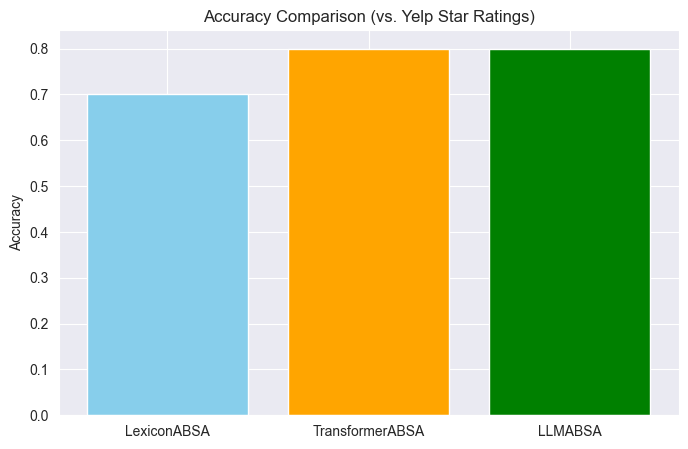

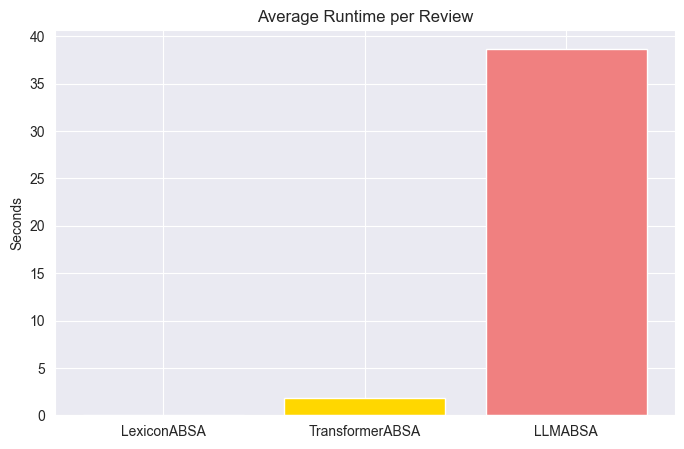

In [12]:
# Visualization of Metrics

plt.figure(figsize=(8,5))
plt.bar(metrics_df["Model"], metrics_df["Accuracy"], color=["skyblue","orange","green"])
plt.title("Accuracy Comparison (vs. Yelp Star Ratings)")
plt.ylabel("Accuracy")
plt.show()

plt.figure(figsize=(8,5))
plt.bar(metrics_df["Model"], metrics_df["Avg_Runtime(s)"], color=["gray","gold","lightcoral"])
plt.title("Average Runtime per Review")
plt.ylabel("Seconds")
plt.show()


In [16]:
# Results Showcase — Side-by-Side Comparison
showcase_examples = [
    """The mushroom risotto was perfection, but the service was slow.
    The atmosphere was cozy and the chocolate cake divine.""",

    """I tried their decaf latte which was tasty, foamy, and light.
    The baristas were friendly but the parking lot was always packed.""",

    """Amazing bagels! My favorite place ever. Super fast cook and donuts are fresh and taste so good!"""
]

def compare_models_on_text(text):
    rows = []
    for model_name, model in [
        ("LexiconABSA", lex_model),
        ("TransformerABSA", trf_model),
        ("LLMABSA", llm_model)
    ]:
        aspects = model.analyze(text)

        if not aspects:
            rows.append({
                "Model": model_name,
                "Aspect": "_No aspects detected_",
                "Sentiment": "",
                "Confidence": ""
            })
        else:
            for a in aspects:
                rows.append({
                    "Model": model_name,
                    "Aspect": a.aspect,
                    "Sentiment": a.sentiment,
                    "Confidence": round(a.confidence, 2)
                })

    return pd.DataFrame(rows)


# Optional: make sure cells don't get truncated
pd.set_option("display.max_colwidth", None)
from IPython.display import HTML, display
display(HTML("<style>.dataframe td { white-space: pre-wrap; }</style>"))


# Display results
for i, review in enumerate(showcase_examples, 1):
    print(f"### Review {i}\n> {review.strip()}\n")
    df_show = compare_models_on_text(review)
    display(df_show)
    print("\n")


### Review 1
> The mushroom risotto was perfection, but the service was slow.
    The atmosphere was cozy and the chocolate cake divine.



,Model,Aspect,Sentiment,Confidence
0,LexiconABSA,mushroom risotto,positive,0.48
1,LexiconABSA,service,negative,0.38
2,LexiconABSA,atmosphere,positive,0.45
3,TransformerABSA,mushroom risotto,positive,1.00
4,TransformerABSA,service,negative,1.00
5,TransformerABSA,atmosphere,positive,0.99
6,LLMABSA,mushroom risotto,positive,0.90
7,LLMABSA,service,negative,0.85
8,LLMABSA,atmosphere,positive,0.80
9,LLMABSA,chocolate cake,positive,0.90




### Review 2
> I tried their decaf latte which was tasty, foamy, and light.
    The baristas were friendly but the parking lot was always packed.



,Model,Aspect,Sentiment,Confidence
0,LexiconABSA,baristas,positive,0.45
1,TransformerABSA,decaf latte,positive,0.99
2,TransformerABSA,baristas,positive,0.99
3,LLMABSA,decaf latte,positive,0.90
4,LLMABSA,baristas,positive,0.85
5,LLMABSA,parking lot,negative,0.80




### Review 3
> Amazing bagels! My favorite place ever. Super fast cook and donuts are fresh and taste so good!



,Model,Aspect,Sentiment,Confidence
0,LexiconABSA,amazing bagels,positive,0.47
1,LexiconABSA,favorite place,positive,0.41
2,LexiconABSA,super fast cook,positive,0.45
3,LexiconABSA,donuts,positive,0.42
4,TransformerABSA,bagels,positive,1.00
5,TransformerABSA,donuts,positive,1.00
6,LLMABSA,bagels,positive,0.90
7,LLMABSA,place,positive,0.95
8,LLMABSA,cook,positive,0.80
9,LLMABSA,donuts,positive,0.85


# Final Conclusions